# TPS · Módulo 2 — Ritmos cerebrales (análisis espectral)
**PSIB 2026Q2 · Grupo 12** — Lautersztein, Reggio, Ballester
*Caracterización de la carga cognitiva mediante análisis espectral del EEG durante aritmética mental*

El Módulo 1 dejó, por sujeto y condición, **15 épocas de 4 s** (realizaciones aproximadamente estacionarias) y marcó cuáles son atípicas. Acá:

1. Estimamos la PSD de cada época con **cuatro estimadores** (periodograma, Welch, Blackman-Tukey y modelo AR con orden elegido por AIC) y los comparamos en los 36 sujetos: resolución, varianza y potencia que asignan a cada banda.
2. Con el estimador elegido calculamos la **potencia por banda** (delta/theta/alfa/beta) por canal y comparamos **reposo vs. tarea**, con y sin las épocas atípicas.

La salida (`modulo2_potencias.csv`) es la entrada del Módulo 3 (mapas topográficos y estadística).

## 0. Carga
Retomamos lo guardado por el Módulo 1 (épocas, marca de atípicas, fs y tabla de sujetos). No hace falta releer los EDF: si se corre en una sesión nueva de Colab, primero correr el Módulo 1 o subir `modulo1_epocas.npz` y `modulo1_sujetos.csv`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import signal

mod1 = np.load('modulo1_epocas.npz')
info = pd.read_csv('modulo1_sujetos.csv')
CANALES, FS = list(mod1['canales']), float(mod1['fs'])
COND = {1: 'reposo', 2: 'tarea'}
epocas  = {(s, c): mod1[f'{s}_{COND[c]}']          for s in info.Subject for c in COND}   # [épocas x canales x muestras]
atipica = {(s, c): mod1[f'{s}_{COND[c]}_atipicas'] for s in info.Subject for c in COND}   # [épocas] bool
BANDAS = {'delta': (0.5, 4), 'theta': (4, 8), 'alfa': (8, 13), 'beta': (13, 30)}
SUJ, CANAL = info.Subject[0], CANALES.index('Pz')       # sujeto y canal de ejemplo para los gráficos

## 1. Cuatro estimadores de la PSD
Todos reciben un arreglo de épocas `[..., muestras]` y devuelven `(f, PSD)` **unilateral** en µV²/Hz (toda la potencia en f ≥ 0), de modo que en los cuatro se cumple $\int_0^{f_s/2} S(f)\,df = \sigma^2$ y las magnitudes son comparables.

| Método | Tipo | Idea | Compromiso |
|---|---|---|---|
| **Periodograma** | no paramétrico | $\lvert X(f)\rvert^2/N$ de la época entera (ventana de Hann) | máxima resolución, varianza ≈ $S^2(f)$: no baja con N (no es consistente) |
| **Welch** | no paramétrico | promedia periodogramas de ventanas de 2 s (Hamming, 50 % de solapamiento) | menos varianza a cambio de resolución (Δf = 0,5 Hz) |
| **Blackman-Tukey** | no paramétrico | transforma la autocorrelación truncada en ±M y ventaneada (Blackman) | M chico → menos varianza, menos resolución |
| **AR (Yule-Walker)** | paramétrico | ajusta $x[n]=\sum a_k x[n-k]+e[n]$ y usa $S(f)=\sigma_e^2/\lvert A(f)\rvert^2$ | espectro suave y buena resolución, pero depende del orden p |

Cada estimador se aplica **época por época** y después se promedia entre las épocas (promedio sobre realizaciones).

In [2]:
NFFT = 2000                                   # puntos de FFT para BT y AR (Δf = 0,25 Hz, igual que el periodograma de 4 s)

def unilateral(f, S):
    """Pasa una PSD bilateral a unilateral: duplica todo menos f = 0 y f = fs/2."""
    S = S.copy()
    S[..., (f > 0) & (f < FS / 2)] *= 2
    return S

def autocorr(x, max_lag):
    """Autocorrelación sesgada r[0..max_lag] de cada serie (último eje), vía FFT: r = IFFT(|X|²) / N."""
    x = x - x.mean(axis=-1, keepdims=True)
    N = x.shape[-1]
    return np.fft.irfft(np.abs(np.fft.rfft(x, 2 * N, axis=-1)) ** 2, axis=-1)[..., :max_lag + 1] / N

def periodograma(x):
    return signal.periodogram(x, FS, window='hann', axis=-1)

def welch(x, ventana_s=2):
    n = int(ventana_s * FS)
    return signal.welch(x, FS, window='hamming', nperseg=n, noverlap=n // 2, axis=-1)

def blackman_tukey(x, m_s=1):
    """Autocorrelación hasta el lag M = m_s·fs, ventaneada con media ventana de Blackman y transformada.
    La secuencia r[-M..M] es par, así que su FFT es real: S(f) = (1/fs)·Σ w[k] r[k] e^{-j2πfk/fs}."""
    M = int(m_s * FS)
    rw = autocorr(x, M) * np.blackman(2 * M + 1)[M:]            # lags 0..M ventaneados (w[0] = 1)
    sec = np.zeros(x.shape[:-1] + (NFFT,))
    sec[..., :M + 1], sec[..., -M:] = rw, rw[..., :0:-1]          # lags positivos al principio, negativos al final
    f = np.fft.rfftfreq(NFFT, 1 / FS)
    return f, unilateral(f, np.fft.rfft(sec, axis=-1).real / FS)

### 1.1 Modelo AR: Levinson-Durbin y orden por AIC
Las ecuaciones de Yule-Walker $\sum_k a_k\, r[i-k] = r[i]$ se resuelven con la **recursión de Levinson-Durbin**, que en cada paso agrega un coeficiente y da la varianza del error de predicción $E_p$ de **todos** los órdenes de una vez. Eso permite elegir el orden con el **criterio de Akaike**: $\mathrm{AIC}(p) = N\ln E_p + 2p$ (el primer término premia el ajuste, el segundo penaliza la cantidad de parámetros).

In [3]:
def levinson(r, orden):
    """Levinson-Durbin vectorizado sobre los ejes iniciales de r [..., orden+1].
    Devuelve los coeficientes a [..., orden] y la varianza del error E [..., orden+1] para cada orden 0..orden."""
    a = np.zeros(r.shape[:-1] + (orden,))
    E = np.zeros(r.shape[:-1] + (orden + 1,))
    E[..., 0] = r[..., 0]
    for k in range(orden):
        acc = r[..., k + 1] - np.sum(a[..., :k] * r[..., k:0:-1], axis=-1)       # r[k+1] - Σ a_j r[k-j]
        kk = acc / E[..., k]                                                      # coeficiente de reflexión
        a[..., :k] -= kk[..., None] * a[..., k - 1::-1] if k else 0
        a[..., k] = kk
        E[..., k + 1] = E[..., k] * (1 - kk ** 2)
    return a, E

def ar_yule_walker(x, orden):
    """PSD paramétrica AR(orden): autocorrelación -> Levinson-Durbin -> σ²/|A(f)|²."""
    a, E = levinson(autocorr(x, orden), orden)
    A = np.fft.rfft(np.concatenate([np.ones(a.shape[:-1] + (1,)), -a], axis=-1), NFFT, axis=-1)
    f = np.fft.rfftfreq(NFFT, 1 / FS)
    return f, unilateral(f, E[..., -1:] / np.abs(A) ** 2 / FS)

Orden óptimo por AIC: mediana = 26, rango intercuartil = [14. 36.]


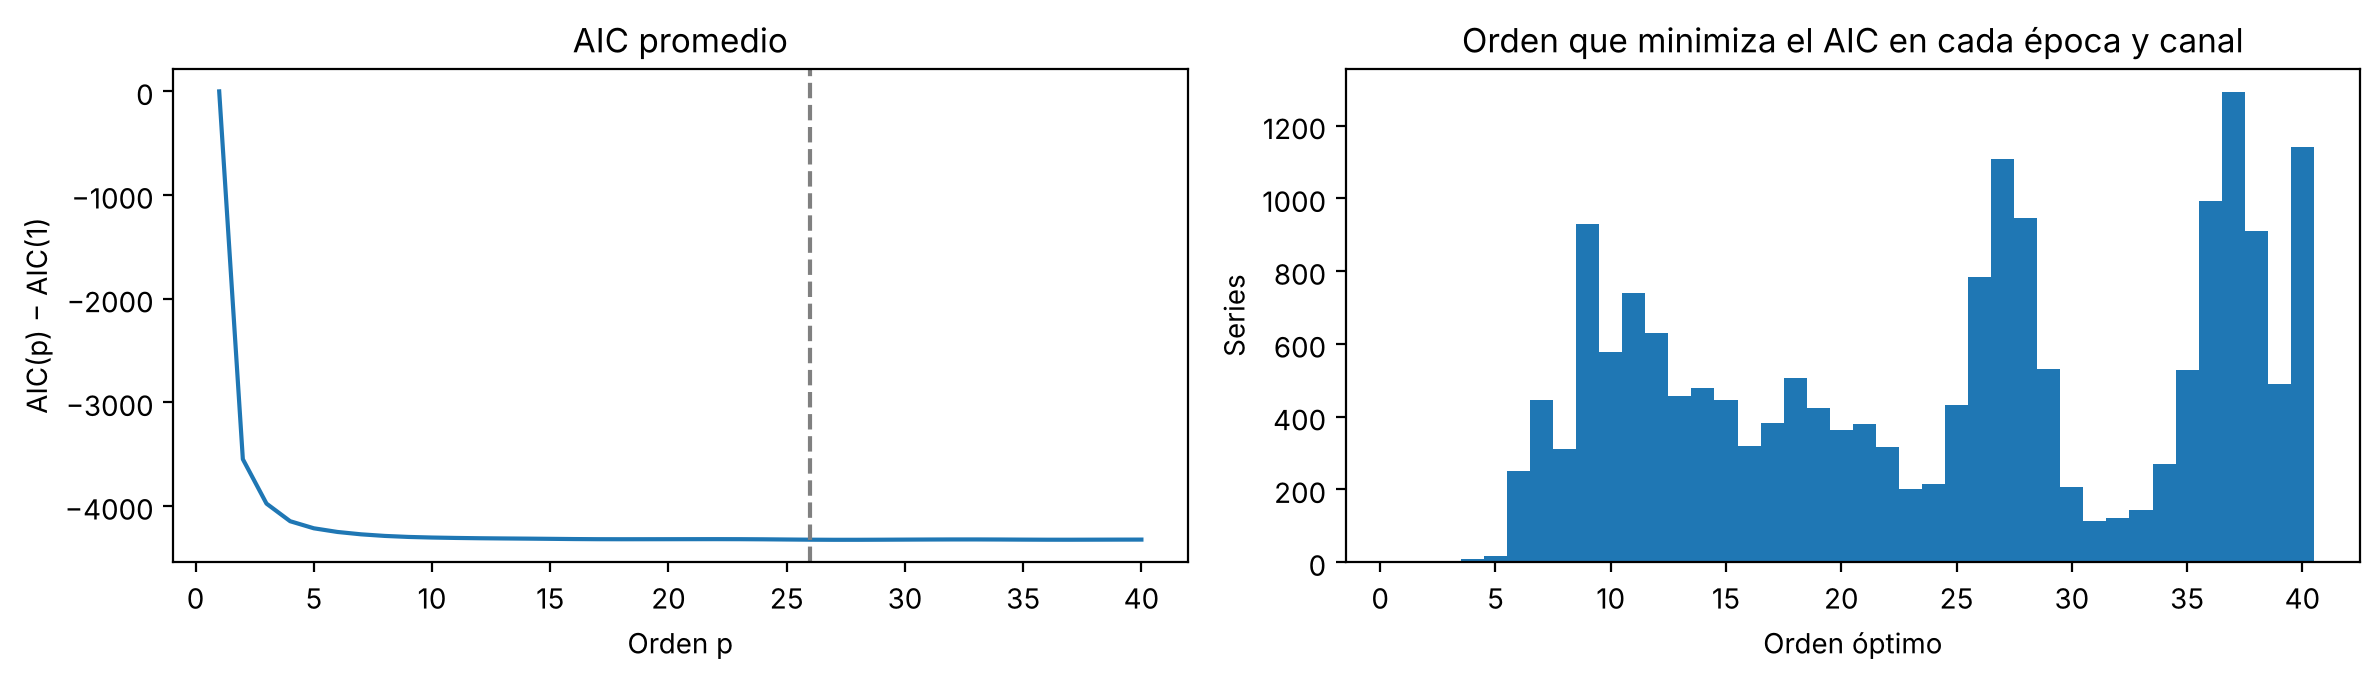

In [4]:
# AIC(p) para todas las épocas no atípicas de todos los sujetos, canales y condiciones (p = 1..40)
P_MAX = 40
todas = np.concatenate([ep[~atipica[k]] for k, ep in epocas.items()])          # [épocas totales x canales x muestras]
N = todas.shape[-1]
_, E = levinson(autocorr(todas, P_MAX), P_MAX)
aic = N * np.log(E[..., 1:]) + 2 * np.arange(1, P_MAX + 1)                      # [épocas x canales x p]
orden_opt = aic.argmin(axis=-1) + 1                                             # orden óptimo de cada serie
ORDEN_AR = int(np.median(orden_opt))
print(f'Orden óptimo por AIC: mediana = {ORDEN_AR}, rango intercuartil = {np.percentile(orden_opt, [25, 75])}')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(range(1, P_MAX + 1), (aic - aic[..., :1]).mean(axis=(0, 1)))
ax[0].axvline(ORDEN_AR, ls='--', c='gray')
ax[0].set(xlabel='Orden p', ylabel='AIC(p) − AIC(1)', title='AIC promedio')
ax[1].hist(orden_opt.ravel(), bins=np.arange(1, P_MAX + 2) - 0.5)
ax[1].set(xlabel='Orden óptimo', ylabel='Series', title='Orden que minimiza el AIC en cada época y canal')
plt.tight_layout()

### 1.2 Comparación visual
Sujeto y canal de ejemplo (Pz, donde el alfa de reposo es fuerte). En gris, el periodograma de cada época por separado: muestra la varianza que los estimadores promediados reducen.

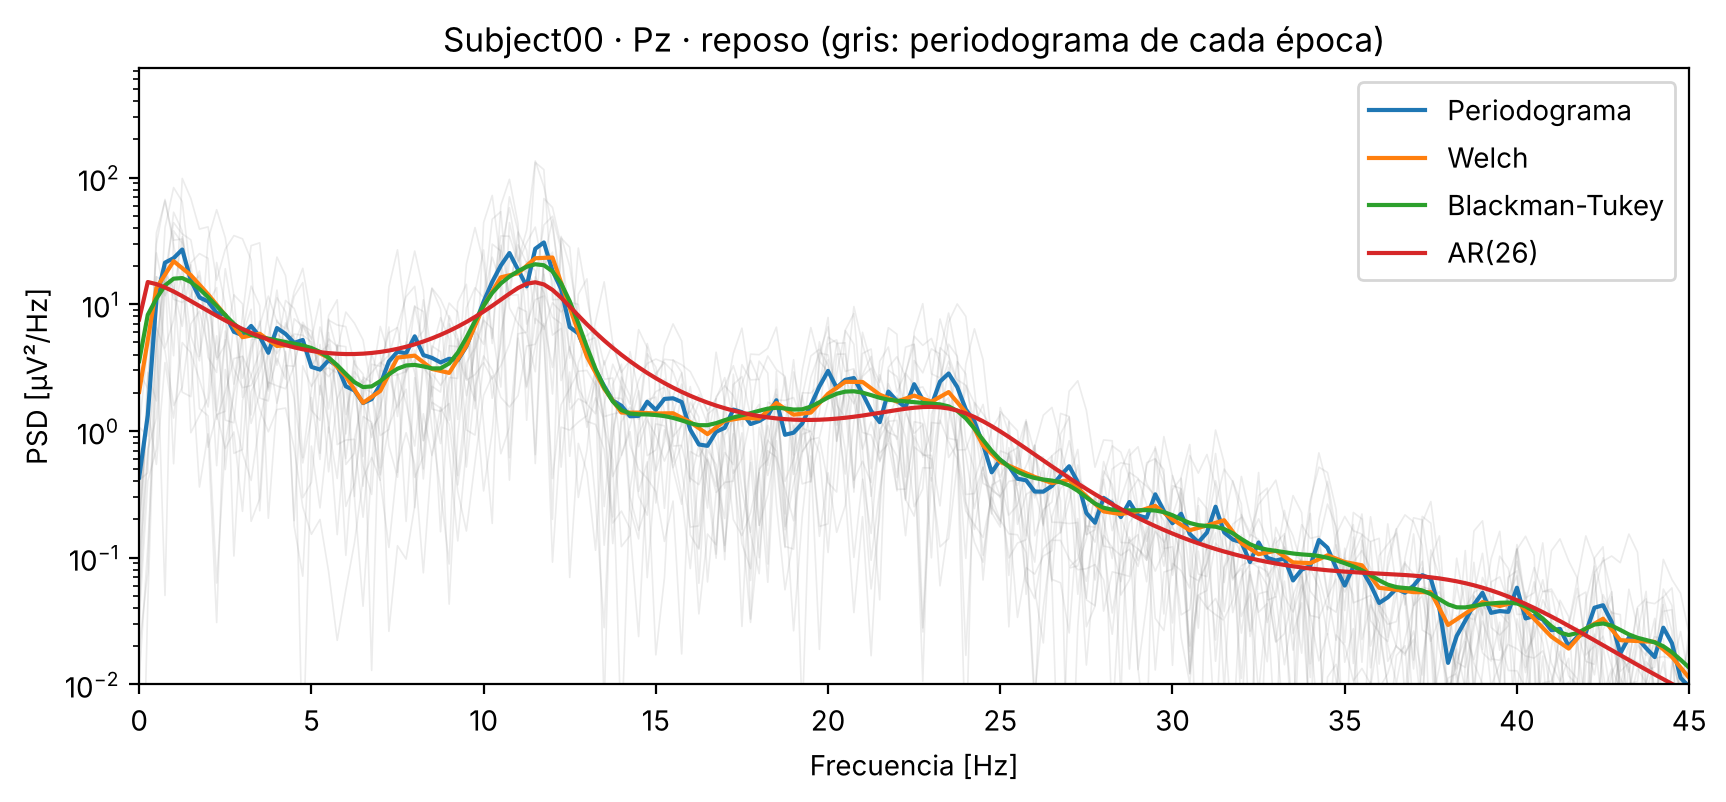

In [5]:
ESTIMADORES = {'Periodograma': periodograma, 'Welch': welch, 'Blackman-Tukey': blackman_tukey,
               f'AR({ORDEN_AR})': lambda x: ar_yule_walker(x, ORDEN_AR)}

ep = epocas[SUJ, 1][~atipica[SUJ, 1], CANAL]                                   # épocas válidas del canal [épocas x muestras]
fig, ax = plt.subplots(figsize=(10, 4))
f_p, P_ep = periodograma(ep)
ax.semilogy(f_p, P_ep.T, color='gray', alpha=0.15, lw=0.6)
for nombre, fun in ESTIMADORES.items():
    f, S = fun(ep)
    ax.semilogy(f, S.mean(axis=0), label=nombre)                                # promedio entre épocas
ax.set(xlim=(0, 45), ylim=(1e-2, None), xlabel='Frecuencia [Hz]', ylabel='PSD [µV²/Hz]',
       title=f'{SUJ} · {CANALES[CANAL]} · reposo (gris: periodograma de cada época)')
ax.legend();

### 1.3 Comparación cuantitativa en los 36 sujetos
Para cada sujeto (canal Pz, reposo) y cada estimador medimos:
- **Escala**: potencia integrada 0,5–45 Hz dividida por la varianza de la señal → ≈ 1 si la PSD está bien normalizada.
- **Pico alfa**: frecuencia del máximo en 8–13 Hz del espectro promediado entre épocas (resolución).
- **Varianza del estimador**: coeficiente de variación de la PSD *entre épocas*, promediado en 1–30 Hz. Para el periodograma la teoría da CV ≈ 1 (su desvío es del orden de la propia PSD); promediar K ventanas lo baja aprox. a $1/\sqrt{K}$. Incluye también la variabilidad real del EEG entre épocas, que es igual para todos los métodos.
- **Alfa relativa**: fracción de la potencia 0,5–30 Hz en 8–13 Hz, para ver si la elección del estimador cambia el resultado que usamos después.

In [6]:
def potencia(f, S, f1, f2):
    """Potencia en [f1, f2): integral de la PSD ≈ Δf · Σ S(f_k)."""
    return S[..., (f >= f1) & (f < f2)].sum(axis=-1) * (f[1] - f[0])

filas = []
for s in info.Subject:
    ep = epocas[s, 1][~atipica[s, 1], CANAL]
    for nombre, fun in ESTIMADORES.items():
        f, S = fun(ep)                                                          # [épocas x f]
        Sm, m = S.mean(axis=0), (f >= 1) & (f <= 30)
        alfa = (f >= 8) & (f <= 13)
        filas.append(dict(sujeto=s, metodo=nombre,
                          escala=potencia(f, Sm, 0.5, 45) / ep.var(axis=-1).mean(),
                          pico_alfa_Hz=f[alfa][Sm[alfa].argmax()],
                          cv_entre_epocas=(S[:, m].std(axis=0) / S[:, m].mean(axis=0)).mean(),
                          alfa_rel=potencia(f, Sm, 8, 13) / potencia(f, Sm, 0.5, 30)))
comp = pd.DataFrame(filas)
comp.drop(columns='sujeto').groupby('metodo', sort=False).agg(['mean', 'std']).round(3)

escala        pico_alfa_Hz        cv_entre_epocas         \
                 mean    std         mean    std            mean    std   
metodo                                                                    
Periodograma    0.986  0.060       10.194  1.222           0.989  0.057   
Welch           0.994  0.034       10.236  1.216           0.664  0.065   
Blackman-Tukey  0.956  0.023       10.167  1.212           0.486  0.066   
AR(26)          0.938  0.034       10.146  1.339           0.365  0.082   

               alfa_rel         
                   mean    std  
metodo                          
Periodograma      0.382  0.167  
Welch             0.380  0.162  
Blackman-Tukey    0.385  0.161  
AR(26)            0.350  0.151

## 2. Potencia por banda
Usamos **Welch** como estimador principal (justificación en las conclusiones). Se aplica a cada época válida y se promedia entre épocas, así ninguna ventana mezcla dos épocas separadas por una atípica descartada. La potencia de cada banda es la **integral** de la PSD en la banda (suma de los bins × Δf): integrar, y no promediar la densidad, es lo que permite comparar bandas de anchos distintos (delta 3,5 Hz, beta 17 Hz).

Calculamos todo dos veces, **excluyendo e incluyendo las épocas atípicas**, para ver si descartarlas cambia el resultado.

In [7]:
def potencia_bandas(sujeto, cond, excluir_atipicas=True):
    """Potencia (µV²) por banda y canal: Welch por época, promedio entre épocas e integral en cada banda."""
    ep = epocas[sujeto, cond]
    f, S = welch(ep[~atipica[sujeto, cond]] if excluir_atipicas else ep)
    S = S.mean(axis=0)                                                          # [canales x f]
    return {b: potencia(f, S, f1, f2) for b, (f1, f2) in BANDAS.items()}

def tabla_potencias(excluir_atipicas):
    pot = pd.DataFrame([dict(sujeto=s, condicion=COND[c], canal=canal, banda=b, potencia=v)
                        for s in info.Subject for c in COND
                        for b, vals in potencia_bandas(s, c, excluir_atipicas).items()
                        for canal, v in zip(CANALES, vals)])
    pot['potencia_rel'] = pot.potencia / pot.groupby(['sujeto', 'condicion', 'canal']).potencia.transform('sum')
    return pot

pot, pot_todas = tabla_potencias(True), tabla_potencias(False)
pot.groupby(['condicion', 'banda'], sort=False).potencia.mean().unstack().round(2)

banda,delta,theta,alfa,beta
condicion,,,,
reposo,47.50,14.59,36.09,12.14
tarea,50.07,13.98,24.83,10.69


In [8]:
# Efecto de excluir las épocas atípicas: potencia relativa media con y sin ellas
pd.concat({'sin atípicas': pot.groupby(['condicion', 'banda'], sort=False).potencia_rel.mean(),
           'con atípicas': pot_todas.groupby(['condicion', 'banda'], sort=False).potencia_rel.mean()},
          axis=1).unstack().round(3)

sin atípicas                      con atípicas                     
banda            delta  theta   alfa   beta        delta  theta   alfa   beta
condicion                                                                    
reposo           0.455  0.143  0.288  0.114        0.471  0.137  0.282  0.110
tarea            0.506  0.152  0.226  0.116        0.525  0.144  0.219  0.111

### 2.1 Reposo vs. tarea
Potencia relativa de cada banda (fracción de delta+theta+alfa+beta), promediada entre canales y sujetos: compara la *distribución* entre bandas sin que la amplitud absoluta, que varía mucho entre sujetos, tape la diferencia.

El denominador es la suma de las cuatro bandas (0,5–30 Hz) y no el total hasta 45 Hz: la banda 30–45 Hz queda pegada al pasa-bajos de la base, donde la PSD ya está atenuada y es poco confiable. El Módulo 4 comprueba que normalizar por 0,5–45 Hz no cambia ninguna decisión estadística.

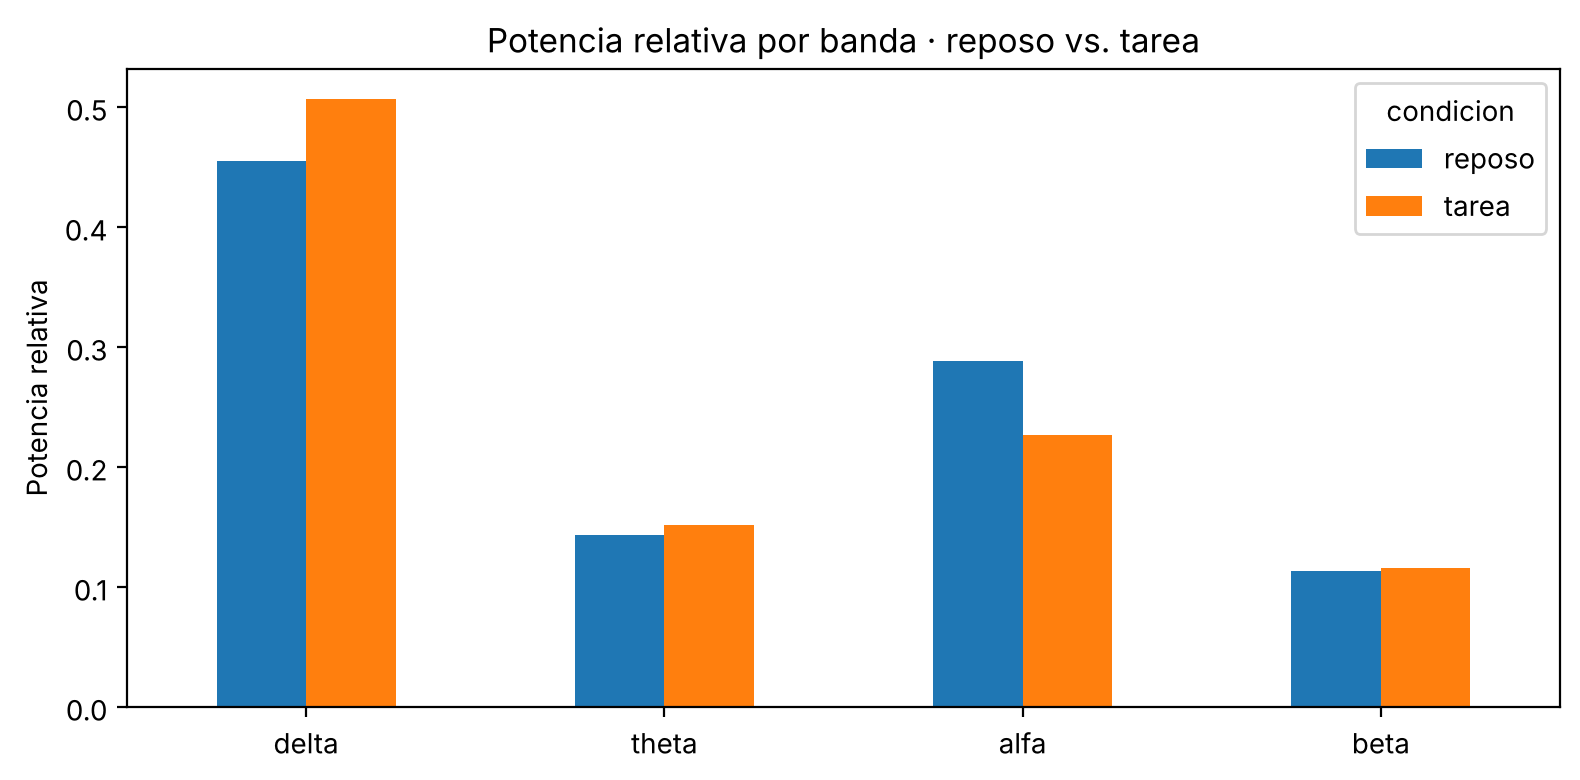

In [9]:
rel = pot.groupby(['condicion', 'banda'], sort=False).potencia_rel.mean().unstack()
ax = rel.T.plot.bar(figsize=(8, 4), rot=0)
ax.set(ylabel='Potencia relativa', xlabel='', title='Potencia relativa por banda · reposo vs. tarea')
plt.tight_layout()

### 2.2 Alfa por canal
Si la carga cognitiva suprime alfa, la caída debería notarse en los canales parietales y occipitales (P3, P4, Pz, O1, O2), donde el alfa de reposo es más fuerte. Mostramos la caída en puntos de potencia relativa (absoluta) y en % del valor de reposo.

In [10]:
alfa = pot[pot.banda == 'alfa'].pivot_table(index='canal', columns='condicion', values='potencia_rel').reindex(CANALES)
alfa['caida_pts'] = alfa.reposo - alfa.tarea
alfa['caida_%'] = 100 * alfa.caida_pts / alfa.reposo
alfa.round(3)

condicion,reposo,tarea,caida_pts,caida_%
canal,,,,
Fp1,0.197,0.129,0.068,34.461
Fp2,0.191,0.133,0.058,30.390
F3,0.242,0.191,0.051,21.092
F4,0.248,0.195,0.053,21.417
F7,0.184,0.138,0.046,24.927
F8,0.187,0.131,0.056,29.984
Fz,0.239,0.190,0.049,20.450
C3,0.277,0.227,0.050,18.133
C4,0.274,0.229,0.045,16.297


## 3. Conclusiones del Módulo 2
*(Corrida sobre los 36 sujetos.)*

**Estimadores (sección 1)**
- **Escala:** los cuatro integran a la varianza de la señal (0,94–0,99), así que están bien normalizados y son comparables en magnitud. El AR queda algo por debajo porque su espectro suave no sigue el pico alfa.
- **Orden AR:** el AIC cae abruptamente hasta p ≈ 8 y después queda casi plano; el orden óptimo varía mucho entre épocas (rango intercuartil 14–36), así que se usa la mediana, **p = 26**. Que la curva sea tan plana indica que más allá de ~10 coeficientes el modelo casi no mejora el ajuste.
- **Varianza:** el CV de la PSD entre épocas confirma la teoría: **periodograma 0,99** (≈ 1, no es consistente), **Welch 0,66** (promedia 3 ventanas solapadas por época), **Blackman-Tukey 0,49** y **AR 0,37**. Menos varianza se paga con resolución: el AR y el BT (lag máximo de 1 s) suavizan el pico alfa.
- **Resolución:** el pico alfa sale en 10,1–10,2 Hz con los cuatro métodos (desvío entre sujetos ≈ 1,2 Hz): para ubicar el pico la elección no importa.
- **Potencia alfa relativa en Pz:** periodograma, Welch y BT coinciden (0,38–0,385); el AR la subestima (0,35) porque reparte la potencia del pico hacia las bandas vecinas.
- **Elección: Welch.** Es el que mejor conserva la escala (0,99), tiene menos varianza que el periodograma sin el sesgo del AR, no depende de elegir un orden y es el estándar en EEG. La comparación completa entre estimadores sobre el resultado estadístico queda para el análisis de sensibilidad (Módulo 4).
- **Épocas como realizaciones:** promediar entre épocas reemplaza el promedio sobre realizaciones (que no tenemos) por un promedio temporal, lo que supone que el proceso es **estacionario y ergódico en la autocorrelación** dentro de los 60 s. Es una aproximación: según el Módulo 1 la media de cada época es estable (varía ≈ 0,6 µV), pero la varianza cambia ≈ 37 % entre épocas, así que la estacionariedad vale sólo dentro de cada época y el promedio suaviza esas variaciones.

**Ritmos (sección 2)**
- **Alfa relativa cae de 0,288 a 0,226 con la tarea** (36,1 → 24,8 µV² en potencia absoluta). Delta es la banda dominante y sube (0,455 → 0,506); theta (0,143 → 0,152) y beta (≈ 0,115) casi no cambian en el promedio global.
- **Por canal**, la caída de alfa en puntos de potencia relativa es mayor en los **parieto-occipitales** (P3 0,100; O1 0,096; Pz 0,089), donde el alfa de reposo es más alto (0,38–0,45). En porcentaje del valor de reposo la mayor caída es frontal (Fp1 34 %, Fp2 30 %, F8 30 %), porque ahí el alfa de base es bajo. Delta relativa sube más en Fp1 y F8; el Módulo 3 muestra que, en potencia absoluta, delta sólo aumenta en la región frontal (+13 %), compatible con movimientos oculares residuales.
- **Épocas atípicas:** incluirlas sube delta ≈ 2 puntos y baja las demás bandas menos de 1 punto, en ambas condiciones por igual; la diferencia reposo − tarea casi no cambia. Se trabaja sin ellas. En las pruebas estadísticas (Módulo 4), incluirlas no invierte ningún efecto significativo: 3 de 50 tests regionales pierden la significancia (beta relativa temporal, delta absoluta frontal y θ/α occipital, con q entre 0,07 y 0,10).
- **Potencia relativa:** se normaliza por 0,5–30 Hz (suma de las cuatro bandas); el Módulo 4 verifica que usar 0,5–45 Hz no cambia ninguna decisión estadística.
- La significancia estadística de estos cambios se evalúa en el Módulo 3.

In [11]:
pot.to_csv('modulo2_potencias.csv', index=False)          # sujeto, condicion, canal, banda, potencia [µV²], potencia_rel